# In-house test-set comparison

Compare the frozen equations with AlphaFold/Boltz ipTM and negative peptide pAE.
Affinity ranking uses **62 real complexes passing both intended-pocket checks**;
ROC analysis uses **62 real + 54 synthetic decoys** from the original test split.

Equations were selected using validation data. This split is not target-disjoint
or screened against predictor training data. Historical log-affinity labels
include **54 Kd and 8 Ki** measurements.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score
from IPython.display import display

%matplotlib inline
sns.set_context('paper')

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/x_y_v2/real_X_test.csv').exists())
DATA = ROOT / 'data/x_y_v2'
ARCHIVE = Path('/mnt/imp_arch/General/Data/personal/er8813ha/immunopeptides/results_ver2_boltz_af')

In [3]:
real = pd.read_csv(DATA / 'real_X_test.csv').merge(
    pd.read_csv(DATA / 'real_y_test.csv')[['complex_filename', 'pKd']],
    on='complex_filename', validate='one_to_one')
shuffle = pd.read_csv(DATA / 'shuffle_X_test.csv')
random = pd.read_csv(DATA / 'random_X_test.csv')

# Use the original intended-pocket flags for the affinity measurements.
raw_real = pd.read_csv(ARCHIVE / '3_scores/scores.csv').set_index('complex_filename')
gate_columns = ['alphafold_in_binding_site', 'boltz_in_binding_site']
flags = raw_real.loc[real.complex_filename, gate_columns]
assert flags.eq(True).all().all(), 'Affinity ranking requires both pocket checks'

all_test = pd.concat([
    real.assign(label=1), shuffle.assign(label=0), random.assign(label=0)
], ignore_index=True)
is_real = all_test.label.eq(1)
affinity = all_test.loc[is_real, 'pKd']
print(f'Affinity: {len(real)} pocket-passing complexes; ROC: {len(all_test)} real/decoy examples.')

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/imp_arch/General/Data/personal/er8813ha/immunopeptides/results_ver2_boltz_af/3_scores/scores.csv'

## Scoring

Apply each fixed expression with its saved training min–max scaler, without
clipping or refitting. Each family product is its own R × C.
The manuscript product uses AlphaFold R (12) and Both C (12), whereas the
saved validation-selected Both C is equation 8.

In [ ]:
def score_equation(frame, family, task, index):
    folder = ROOT / f'plots_v2_{family}' / task
    equations = pd.read_csv(folder / f'symbolic_{task}_all_equations.csv')
    equation = equations.set_index('equation_index').loc[index, 'equation']
    scaler = pd.read_csv(folder / 'scaling_params.csv', index_col=0)
    scaler = scaler.loc[scaler.index.intersection(frame.columns)]
    scaled = (frame[scaler.index] - scaler['min']) / (scaler['max'] - scaler['min'])
    return scaled.eval(equation, engine='python')


SELECTED = {
    'boltz': {'regression': 4, 'classification': 9},
    'alphafold': {'regression': 12, 'classification': 14},
    'both': {'regression': 13, 'classification': 8},
}
scores = pd.DataFrame(index=all_test.index)
for family, tasks in SELECTED.items():
    for task, index in tasks.items():
        scores[f'{family}_{task}'] = score_equation(all_test, family, task, index)
    scores[f'{family}_product'] = scores[f'{family}_regression'] * scores[f'{family}_classification']

manuscript_c = score_equation(all_test, 'both', 'classification', 12)
scores['manuscript_product'] = scores.alphafold_regression * manuscript_c
for method in ['boltz', 'alphafold']:
    scores[f'{method}_iptm'] = all_test[f'{method}_iptm']
    scores[f'{method}_negative_pae'] = -all_test[f'{method}_peptide_pae']
assert np.isfinite(scores.to_numpy()).all(), 'All methods must score every test observation'

## Test performance

Larger scores predict stronger binding. Correlations use the real complexes;
AUROC and average precision use the original real/synthetic-decoy labels.

In [ ]:
CASES = {
    'boltz_regression': 'Boltz R',
    'alphafold_regression': 'AlphaFold R',
    'both_regression': 'Both R',
    'boltz_classification': 'Boltz C',
    'alphafold_classification': 'AlphaFold C',
    'both_classification': 'Both C',
    'boltz_product': 'Boltz R×C',
    'alphafold_product': 'AlphaFold R×C',
    'both_product': 'Both R×C',
    'manuscript_product': 'Manuscript mixed R×C',
    'boltz_iptm': 'Boltz ipTM',
    'alphafold_iptm': 'AlphaFold ipTM',
    'boltz_negative_pae': 'Boltz −peptide pAE',
    'alphafold_negative_pae': 'AlphaFold −peptide pAE',
}
summary = pd.DataFrame([{
    'score_id': key, 'Score': label, 'n_affinity': len(real),
    'Pearson r': pearsonr(affinity, scores.loc[is_real, key]).statistic,
    'Spearman ρ': spearmanr(affinity, scores.loc[is_real, key]).statistic,
    'n_ROC': len(all_test), 'AUROC': roc_auc_score(all_test.label, scores[key]),
    'AP': average_precision_score(all_test.label, scores[key]),
} for key, label in CASES.items()]).set_index('score_id')
display(summary.round(3))

,Score,n_affinity,Pearson r,Spearman ρ,n_ROC,AUROC,AP
score_id,,,,,,,
boltz_regression,Boltz R,62,0.470,0.485,116,0.681,0.674
alphafold_regression,AlphaFold R,62,0.520,0.484,116,0.729,0.748
both_regression,Both R,62,0.514,0.466,116,0.681,0.742
boltz_classification,Boltz C,62,0.048,0.082,116,0.883,0.912
alphafold_classification,AlphaFold C,62,0.175,0.224,116,0.927,0.943
both_classification,Both C,62,0.187,0.231,116,0.919,0.943
boltz_product,Boltz R×C,62,0.181,0.188,116,0.884,0.911
alphafold_product,AlphaFold R×C,62,0.329,0.333,116,0.928,0.944
both_product,Both R×C,62,0.338,0.331,116,0.916,0.940


## Regression plots

All panels use the same pocket-passing complexes. Lines are descriptive fits.

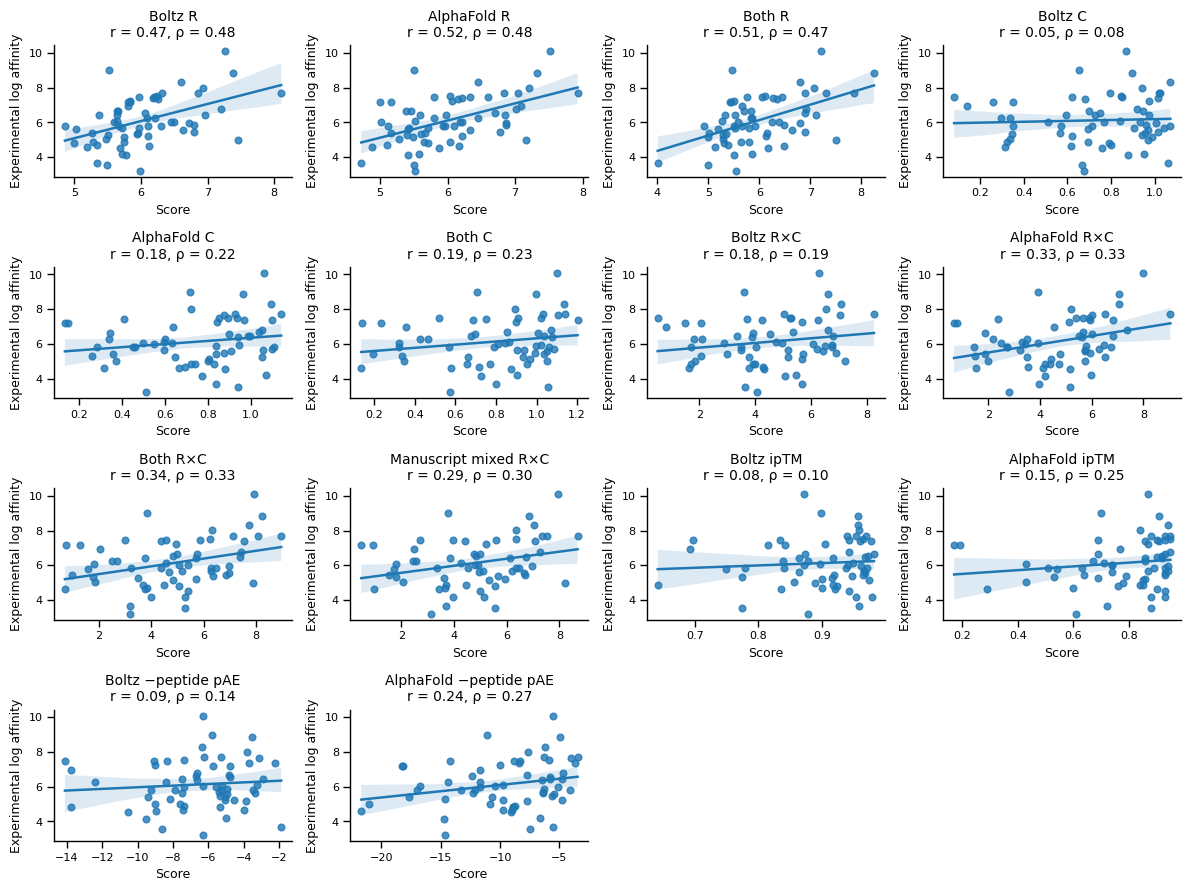

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(12, 9))
for ax, (key, label) in zip(axes.flat, CASES.items()):
    sns.regplot(x=scores.loc[is_real, key], y=affinity, ax=ax)
    row = summary.loc[key]
    ax.set_title(f'{label}\nr = {row["Pearson r"]:.2f}, ρ = {row["Spearman ρ"]:.2f}', fontsize=10)
    ax.set_xlabel('Score', fontsize=9)
    ax.set_ylabel('Experimental log affinity', fontsize=9)
    ax.tick_params(labelsize=8)
    sns.despine(ax=ax)
for ax in axes.flat[len(CASES):]:
    ax.set_visible(False)
fig.tight_layout()

## ROC curves

All panels use the same real/decoy test examples; the diagonal is AUROC = 0.5.

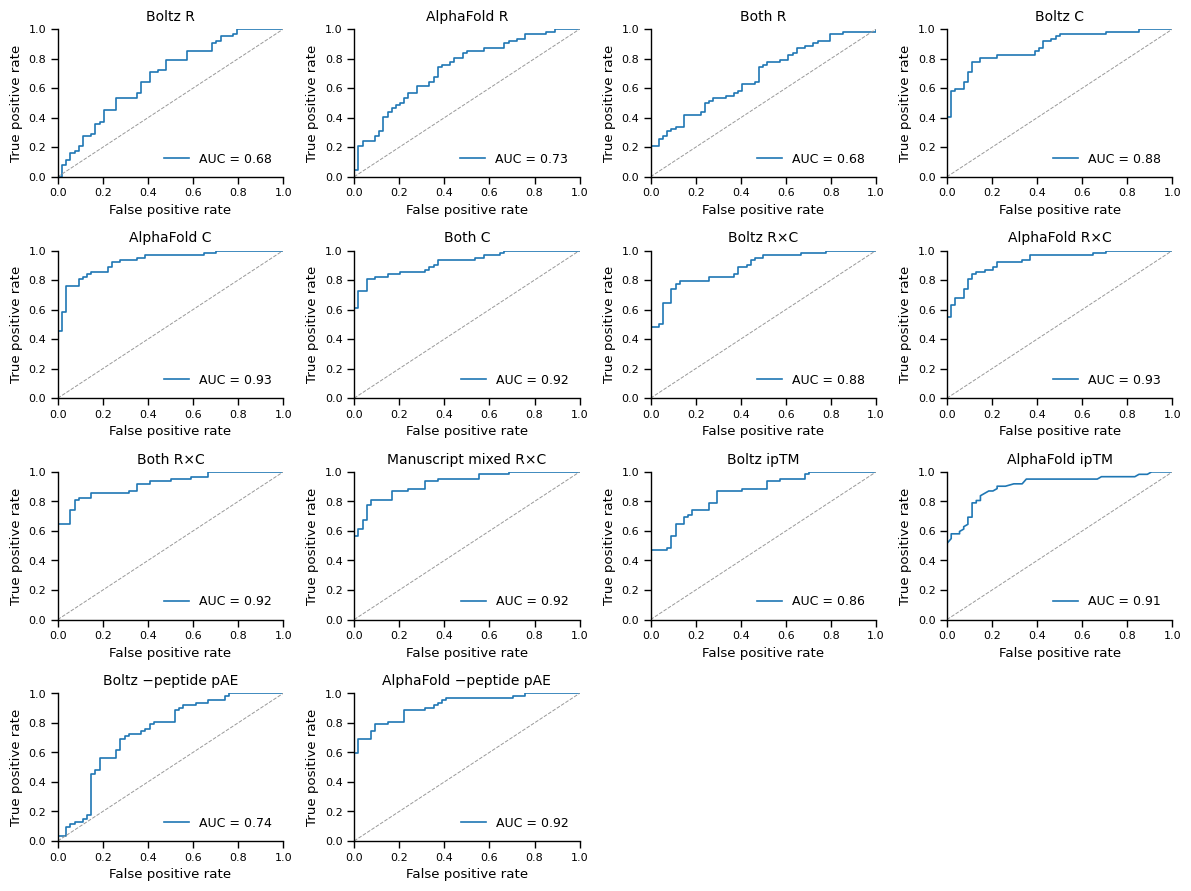

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(12, 9))
for ax, (key, label) in zip(axes.flat, CASES.items()):
    fpr, tpr, _ = roc_curve(all_test.label, scores[key])
    ax.plot(fpr, tpr,
            label=f'AUC = {summary.loc[key, "AUROC"]:.2f}')
    ax.plot([0, 1], [0, 1], color='.6', linestyle='--', linewidth=.7)
    ax.set_title(label, fontsize=10)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='False positive rate', ylabel='True positive rate')
    ax.tick_params(labelsize=8)
    ax.legend(loc='lower right', frameon=False, fontsize=9)
    sns.despine(ax=ax)
for ax in axes.flat[len(CASES):]:
    ax.set_visible(False)
fig.tight_layout()


## Target overlap with equation training data

Check the **receptor sequence**, not just the peptide or PDB ID. Training targets
include real, shuffled and random examples because the classifier can see a target
through a decoy. Training + validation is a stricter reference: validation targets
were available during equation selection.

- **Exact unseen:** no identical receptor sequence in the reference split(s).
- **Homology unseen:** no MMseqs2 hit with ≥30% identity, ≥80% coverage of the test
  receptor and E-value ≤0.001, and no exact match. Coverage is relative to the test
  receptor so a longer training construct can still count as seen. Search sensitivity
  is 7.5; these criteria are fixed independently of subgroup performance.

These are post-hoc, sequence-defined subgroups of the existing test set. We keep
all equations fixed. Absence from our equation-fitting data does **not** establish
absence from AlphaFold/Boltz training, and an undetected homology hit is not proof
of no evolutionary relationship.

In [4]:
import hashlib
import shutil
import subprocess
import tempfile

metadata = pd.read_csv(ARCHIVE / '1_processed_complexes/processed_pdbs.csv')
assert metadata.groupby('pdb_code').protein_sequence.nunique().eq(1).all()
receptors = metadata.drop_duplicates('pdb_code').set_index('pdb_code').protein_sequence

split_rows = []
for split in ['train', 'val', 'test']:
    for kind in ['real', 'shuffle', 'random']:
        frame = pd.read_csv(DATA / f'{kind}_X_{split}.csv')[['complex_filename']]
        frame['split'], frame['kind'] = split, kind
        frame['pdb_code'] = frame.complex_filename.str.split('_', n=1).str[0]
        frame['target_sequence'] = frame.pdb_code.map(receptors)
        split_rows.append(frame)
membership = pd.concat(split_rows, ignore_index=True)
assert membership.target_sequence.notna().all()
membership['target_id'] = membership.target_sequence.map(
    lambda sequence: 't_' + hashlib.sha256(sequence.encode()).hexdigest()[:16])
assert membership.groupby('target_id').target_sequence.nunique().eq(1).all()

training = membership.loc[membership.split.eq('train')]
development = membership.loc[membership.split.isin(['train', 'val'])]
target_audit = membership.loc[membership.split.eq('test')].copy()
for label, reference in [('train', training), ('train_val', development)]:
    target_audit[f'seen_exact_{label}'] = target_audit.target_id.isin(reference.target_id)
    target_audit[f'same_pdb_{label}'] = target_audit.pdb_code.isin(reference.pdb_code)

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/imp_arch/General/Data/personal/er8813ha/immunopeptides/results_ver2_boltz_af/1_processed_complexes/processed_pdbs.csv'

In [ ]:
MMSEQS = shutil.which('mmseqs') or '/srv/data1/general/localcolabfold/colabfold-conda/bin/mmseqs'
hit_columns = ['query', 'target', 'identity', 'alignment_length', 'query_length',
               'target_length', 'query_coverage', 'target_coverage', 'evalue', 'bits']
with tempfile.TemporaryDirectory(prefix='revision2_target_overlap_') as temporary:
    temporary = Path(temporary)
    for name, frame in [('queries', target_audit), ('reference', development)]:
        unique = frame.drop_duplicates('target_id')
        (temporary / f'{name}.fasta').write_text(''.join(
            f'>{row.target_id}\n{row.target_sequence}\n' for row in unique.itertuples()))
    command = [MMSEQS, 'easy-search', str(temporary / 'queries.fasta'),
               str(temporary / 'reference.fasta'), str(temporary / 'hits.tsv'),
               str(temporary / 'work'), '--min-seq-id', '0.30', '-c', '0.80',
               '--cov-mode', '2', '-e', '0.001', '-s', '7.5', '--alignment-mode', '3',
               '--max-seqs', '10000', '--threads', '2', '--format-output',
               'query,target,fident,alnlen,qlen,tlen,qcov,tcov,evalue,bits']
    result = subprocess.run(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if result.returncode:
        raise RuntimeError(result.stdout[-2000:])
    hits = pd.read_csv(temporary / 'hits.tsv', sep='\t', names=hit_columns)

hits = hits.loc[hits.identity.ge(.30) & hits.query_coverage.ge(.80) & hits.evalue.le(.001)]
for label, reference in [('train', training), ('train_val', development)]:
    matched = hits.loc[hits.target.isin(reference.target_id), 'query']
    target_audit[f'seen_similar_{label}'] = (
        target_audit[f'seen_exact_{label}'] | target_audit.target_id.isin(matched))

target_audit = target_audit.set_index('complex_filename').loc[all_test.complex_filename].reset_index()
target_audit.index = all_test.index
print('MMseqs2:', subprocess.check_output([MMSEQS, 'version'], text=True).strip())

MMseqs2: 17.b804f


In [5]:
SUBSETS = {
    'All test': pd.Series(True, index=all_test.index),
    'Exact unseen: training': ~target_audit.seen_exact_train,
    'Exact unseen: training + validation': ~target_audit.seen_exact_train_val,
    'Homology unseen: training': ~target_audit.seen_similar_train,
    'Homology unseen: training + validation': ~target_audit.seen_similar_train_val,
}
target_counts = pd.DataFrame([{
    'Subset': name,
    'Real affinity observations': int((mask & is_real).sum()),
    'Synthetic decoys': int((mask & ~is_real).sum()),
    'Unique real receptor sequences': target_audit.loc[mask & is_real, 'target_id'].nunique(),
} for name, mask in SUBSETS.items()]).set_index('Subset')
display(target_counts)

strict_unseen = SUBSETS['Homology unseen: training + validation'] & is_real
display(target_audit.loc[strict_unseen, ['complex_filename', 'pdb_code']].reset_index(drop=True))

subgroup_rows = []
for subset, mask in SUBSETS.items():
    affinity_mask = mask & is_real
    y = all_test.loc[affinity_mask, 'pKd']
    labels = all_test.loc[mask, 'label']
    for key, name in CASES.items():
        x = scores.loc[affinity_mask, key]
        valid_correlation = len(x) >= 3 and x.nunique() > 1 and y.nunique() > 1
        two_classes = labels.nunique() == 2
        subgroup_rows.append({
            'Subset': subset, 'score_id': key, 'Score': name,
            'n_affinity': len(y), 'n_decoys': int((labels == 0).sum()),
            'Pearson r': pearsonr(y, x).statistic if valid_correlation else np.nan,
            'Spearman ρ': spearmanr(y, x).statistic if valid_correlation else np.nan,
            'AUROC': roc_auc_score(labels, scores.loc[mask, key]) if two_classes else np.nan,
            'AP': average_precision_score(labels, scores.loc[mask, key]) if two_classes else np.nan,
        })
target_performance = pd.DataFrame(subgroup_rows)
display(target_performance.pivot(index='Score', columns='Subset', values='Spearman ρ')
        .reindex(list(CASES.values())).round(3))
display(target_performance.pivot(index='Score', columns='Subset', values='AUROC')
        .reindex(list(CASES.values())).round(3))

NameError: name 'all_test' is not defined

The homology-screened subsets are very small; their correlations and ROC values
are descriptive. In particular, the strict training + validation subset has only
four real complexes and one synthetic decoy. A large value on that subset is not
strong evidence of generalization.

The following plots show the larger **exact-sequence-unseen training subset**.
Some targets in it still have homologs in training; the tables above keep that
distinction explicit.

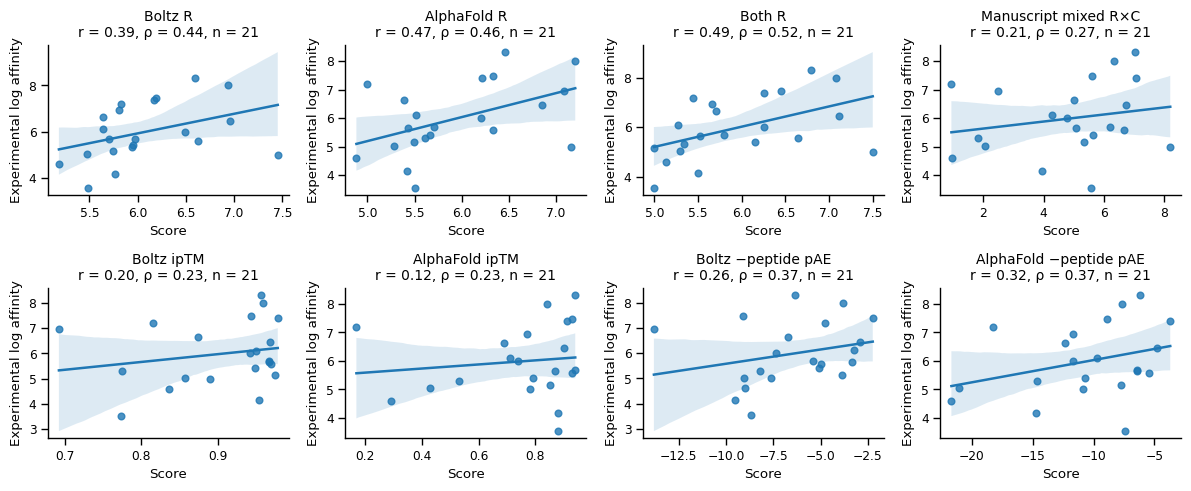

In [ ]:
unseen = SUBSETS['Exact unseen: training']
unseen_real = unseen & is_real
RANK_CASES = ['boltz_regression', 'alphafold_regression', 'both_regression', 'manuscript_product',
              'boltz_iptm', 'alphafold_iptm', 'boltz_negative_pae', 'alphafold_negative_pae']
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, key in zip(axes.flat, RANK_CASES):
    x, y = scores.loc[unseen_real, key], all_test.loc[unseen_real, 'pKd']
    sns.regplot(x=x, y=y, ax=ax)
    ax.set_title(f'{CASES[key]}\nr = {pearsonr(y, x).statistic:.2f}, '
                 f'ρ = {spearmanr(y, x).statistic:.2f}, n = {len(y)}', fontsize=10)
    ax.set(xlabel='Score', ylabel='Experimental log affinity')
    sns.despine(ax=ax)
fig.tight_layout()

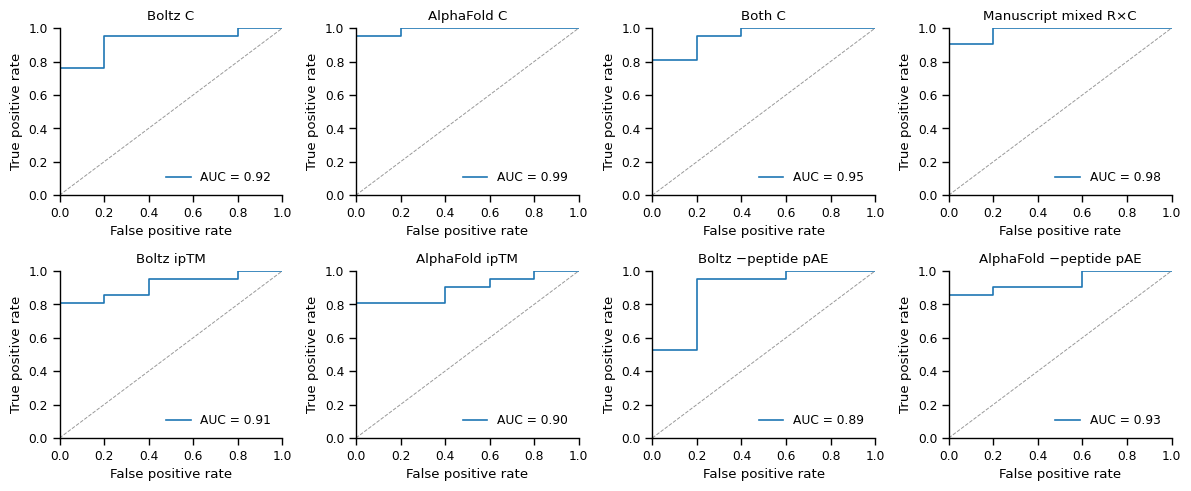

In [ ]:
ROC_CASES = ['boltz_classification', 'alphafold_classification', 'both_classification',
             'manuscript_product', 'boltz_iptm', 'alphafold_iptm',
             'boltz_negative_pae', 'alphafold_negative_pae']
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, key in zip(axes.flat, ROC_CASES):
    labels, prediction = all_test.loc[unseen, 'label'], scores.loc[unseen, key]
    fpr, tpr, _ = roc_curve(labels, prediction)
    ax.plot(fpr, tpr, label=f'AUC = {roc_auc_score(labels, prediction):.2f}')
    ax.plot([0, 1], [0, 1], color='.6', linestyle='--', linewidth=.7)
    ax.set(title=CASES[key], xlim=(0, 1), ylim=(0, 1),
           xlabel='False positive rate', ylabel='True positive rate')
    ax.legend(loc='lower right', frameon=False)
    sns.despine(ax=ax)
fig.tight_layout()

# Similarity-split analysis

Train on 488 real complexes and 434 decoys (training + validation); test on
129 real complexes and 94 decoys. Real complexes retain both intended-pocket
checks. Fit R and C for AF, Boltz, and Both using only interaction/confidence
features (12, 22, and 34 features).

The split groups shared PDB sources, identical sequences, receptor matches
(≥30% identity, ≥80% coverage of either sequence, E-value ≤0.001), and peptide
matches (global edit similarity ≥0.8). These groups do not cross train/test.

Use every final expression and within-family R × C pair. Pearson r uses real
complexes; AUROC uses real complexes and decoys. Boxes show the median, IQR,
and full range of defined scores; constant R expressions have undefined Pearson r.


In [6]:
from pathlib import Path
import importlib
import json
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/x_y_v2').exists())
sys.path.insert(0, str(ROOT / 'src/binding_score_function/predictive_equation'))
import interaction_confidence_fit as fit
importlib.reload(fit)
from interaction_confidence_analysis import evaluate_candidates

DATA = ROOT / 'data/x_y_v2'
RUN_DIR = ROOT / 'outputs/revision2_interaction_confidence_six'


In [7]:
split = pd.read_csv(ROOT / 'outputs/revision2_similarity_holdout/split_membership.csv',
                    index_col='complex_filename')
split['split'] = split.split.replace({'val': 'train'})
assert split.groupby('similarity_group').split.nunique().eq(1).all()

X = pd.concat(pd.read_csv(DATA / f'{kind}_X_{part}.csv', index_col='complex_filename')
              for kind in ['real', 'shuffle', 'random'] for part in ['train', 'val', 'test'])
X = X.loc[split.index, fit.FEATURE_SCHEMAS['both']]
y = pd.concat(pd.read_csv(DATA / f'real_y_{part}.csv', index_col='complex_filename').pKd
              for part in ['train', 'val', 'test'])
train = split.split.eq('train')


In [8]:
# Load the saved six fits, or fit all six using training data only.
model_path = RUN_DIR / 'candidate_models.json'
if model_path.exists():
    models = json.loads(model_path.read_text())
else:
    models = fit.fit_candidate_lists(
        X.loc[train], split.loc[train], y.loc[split.index[train & split.kind.eq('real')]],
        RUN_DIR, niterations=100, seed=42)


In [9]:
scores, baselines = evaluate_candidates(models, X, split, y)

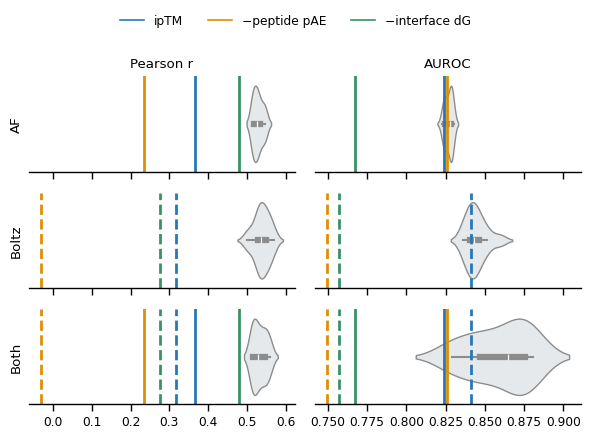

In [28]:
colors = {'ipTM': '#2878B5', '−peptide pAE': '#DE8F05', '−interface dG': '#399264'}
fig, axes = plt.subplots(3, 2, figsize=(6,4), sharex='col')
for row, (family, label) in enumerate([('alphafold', 'AF'), ('boltz', 'Boltz'), ('both', 'Both')]):
    for col, metric in enumerate(['Pearson r', 'AUROC']):
        ax = axes[row, col]
        order = ['R'] if col == 0 else ['C']
        sns.violinplot(data=scores.query('family == @family and metric == @metric'),
                    x='estimate', y='kind', order=order, color='#E5E9EC',
                   linewidth=1, ax=ax)
        for baseline in baselines.query('family == @family and metric == @metric').itertuples():
            source, name = baseline.baseline.split(' ', 1)
            style = '--' if source == 'Boltz' else '-'
            ax.axvline(baseline.estimate, color=colors[name], linestyle=style, linewidth=2)
        ax.set(xlabel='', yticks=[], ylabel=label if col == 0 else '', title=metric if row == 0 else '')
        sns.despine(ax=ax, left=True)

fig.legend(handles=[Line2D([], [], color=color, label=name) for name, color in colors.items()],
           loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(.5, 1.1))
fig.tight_layout()
